In [3]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score
)

# Pondération des classes pour tenir compte du déséquilibre
nb_licites = (y_train == 0).sum()
nb_illicites = (y_train == 1).sum()
poids_classe = nb_licites / nb_illicites

model_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=poids_classe,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("Entraînement du modèle en cours...")
model_xgb.fit(X_train, y_train)

y_pred = model_xgb.predict(X_test)
y_proba = model_xgb.predict_proba(X_test)[:, 1]

print("\n=== RAPPORT DE CLASSIFICATION ===")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Licite", "Illicite"],
    zero_division=0
))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("Balanced accuracy :",
      round(balanced_accuracy_score(y_test, y_pred), 4))
print("Average precision :",
      round(average_precision_score(y_test, y_proba), 4))
print("ROC-AUC :",
      round(roc_auc_score(y_test, y_proba), 4))


Entraînement du modèle en cours...

=== RAPPORT DE CLASSIFICATION ===
              precision    recall  f1-score   support

      Licite       0.61      0.74      0.67      1083
    Illicite       0.98      0.97      0.97     15587

    accuracy                           0.95     16670
   macro avg       0.80      0.85      0.82     16670
weighted avg       0.96      0.95      0.95     16670

Matrice de confusion :
[[  804   279]
 [  509 15078]]
Balanced accuracy : 0.8549
Average precision : 0.9949
ROC-AUC : 0.9381


In [8]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    r"C:\Users\hisse\blockchain-fraud-detection\data\raw\archive\elliptic_bitcoin_dataset"
)

# Charger les classes
classes = pd.read_csv(DATA_DIR / "elliptic_txs_classes.csv")
classes["class"] = classes["class"].astype(str)

# Conserver uniquement les transactions étiquetées
labels = classes[classes["class"].isin(["1", "2"])].copy()
labels["target"] = labels["class"].map({"1": 0, "2": 1})

# Charger les caractéristiques
features = pd.read_csv(
    DATA_DIR / "elliptic_txs_features.csv",
    header=None
)

features.columns = (
    ["txId", "time_step"] +
    [f"feature_{i}" for i in range(1, features.shape[1] - 1)]
)

# Fusionner les caractéristiques et les classes
dataset = labels[["txId", "target"]].merge(
    features,
    on="txId",
    how="inner",
    validate="one_to_one"
)

# Séparer les périodes pour l'entraînement et le test
train_df = dataset[dataset["time_step"] <= 34].copy()
test_df = dataset[dataset["time_step"] > 34].copy()

feature_cols = [
    col for col in dataset.columns
    if col not in ["txId", "target"]
]

X_train = train_df[feature_cols]
y_train = train_df["target"]
X_test = test_df[feature_cols]
y_test = test_df["target"]

print("Données préparées !")
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)



Données préparées !
X_train : (29894, 166)
X_test : (16670, 166)
y_train : (29894,)
y_test : (16670,)


In [9]:
print(X_test.shape)

(16670, 166)


In [10]:
print("XGBoost disponible :", "model_xgb" in globals())

XGBoost disponible : True


In [5]:

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score
)

# Normaliser les caractéristiques pour le réseau de neurones
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Pondérer les classes pour l'entraînement
weights = compute_sample_weight("balanced", y_train)

# Construire le réseau de neurones
model_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=100,
    random_state=42,
    early_stopping=False
)

print("Entraînement du réseau de neurones...")

model_mlp.fit(
    X_train_scaled,
    y_train,
    sample_weight=weights
)

# Évaluer sur le même jeu de test
y_pred_mlp = model_mlp.predict(X_test_scaled)
y_proba_mlp = model_mlp.predict_proba(X_test_scaled)[:, 1]

print("\n=== RAPPORT DU RÉSEAU DE NEURONES ===")
print(classification_report(
    y_test,
    y_pred_mlp,
    labels=[0, 1],
    target_names=["Licite", "Illicite"],
    zero_division=0
))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred_mlp, labels=[0, 1]))

print("Balanced accuracy :",
      round(balanced_accuracy_score(y_test, y_pred_mlp), 4))
print("Average precision :",
      round(average_precision_score(y_test, y_proba_mlp), 4))
print("ROC-AUC :",
      round(roc_auc_score(y_test, y_proba_mlp), 4))


Entraînement du réseau de neurones...

=== RAPPORT DU RÉSEAU DE NEURONES ===
              precision    recall  f1-score   support

      Licite       0.76      0.64      0.69      1083
    Illicite       0.98      0.99      0.98     15587

    accuracy                           0.96     16670
   macro avg       0.87      0.81      0.84     16670
weighted avg       0.96      0.96      0.96     16670

Matrice de confusion :
[[  695   388]
 [  222 15365]]
Balanced accuracy : 0.8137
Average precision : 0.9914
ROC-AUC : 0.9177


C:\Users\hisse\blockchain-fraud-detection\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:

import shap
import pandas as pd

print("Calcul des importances SHAP...")

X_explique = X_test.sample(n=100, random_state=42)

explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer.shap_values(X_explique)

importance_shap = pd.DataFrame({
    "Caracteristique": X_explique.columns,
    "Importance_SHAP": abs(shap_values).mean(axis=0)
})

importance_shap = importance_shap.sort_values(
    "Importance_SHAP",
    ascending=False
)

print("Top 10 des caractéristiques importantes :")
display(importance_shap.head(10))


Calcul des importances SHAP...
Top 10 des caractéristiques importantes :


,Caracteristique,Importance_SHAP
53,feature_53,0.933359
59,feature_59,0.522545
125,feature_125,0.481936
90,feature_90,0.369720
46,feature_46,0.330204
161,feature_161,0.285187
16,feature_16,0.269494
58,feature_58,0.257939
55,feature_55,0.220540
3,feature_3,0.210260


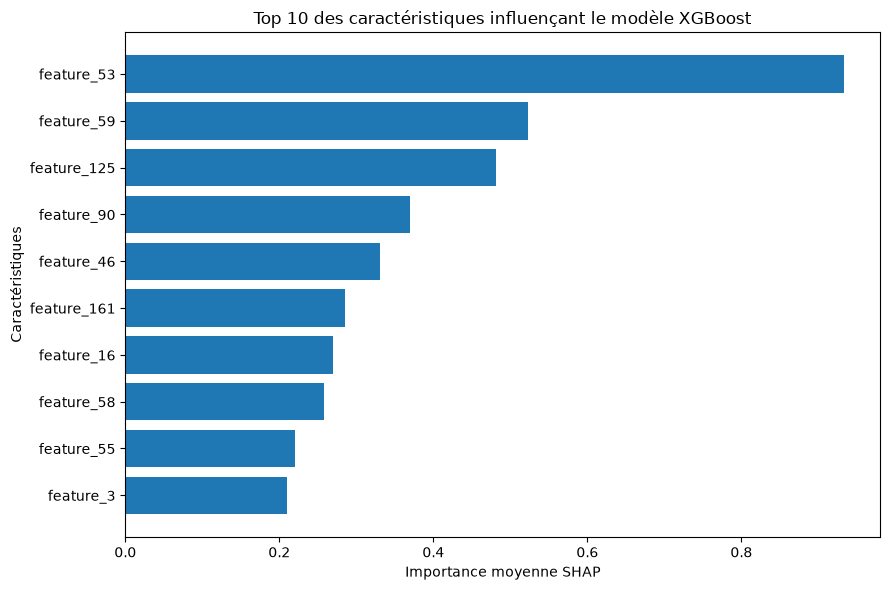

In [12]:
import matplotlib.pyplot as plt

top10 = importance_shap.head(10).sort_values("Importance_SHAP")

plt.figure(figsize=(9, 6))
plt.barh(top10["Caracteristique"], top10["Importance_SHAP"])
plt.xlabel("Importance moyenne SHAP")
plt.ylabel("Caractéristiques")
plt.title("Top 10 des caractéristiques influençant le modèle XGBoost")
plt.tight_layout()
plt.show()

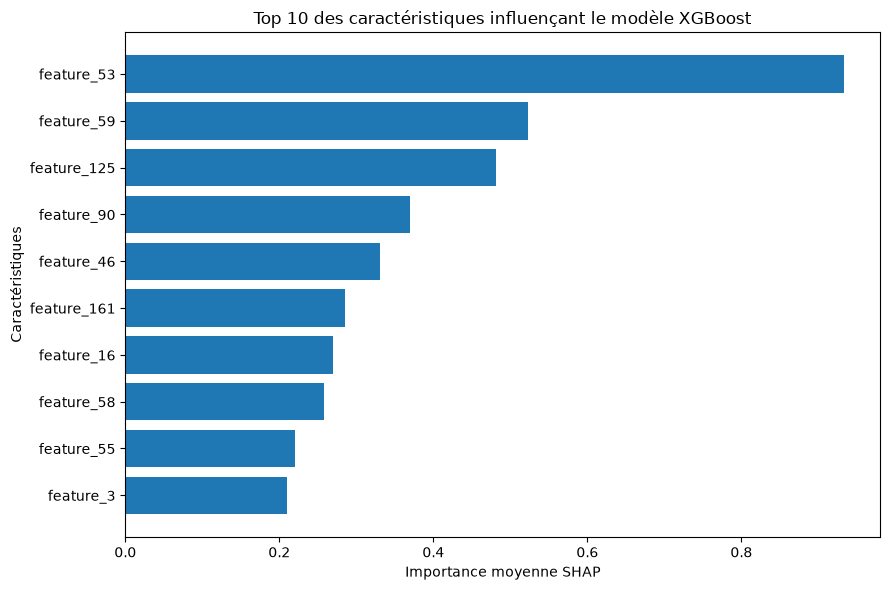

In [14]:
print("=== COMPARAISON DES MODÈLES ===")
print(f"XGBoost - Balanced Accuracy : {0.8549:.4f}")
print(f"XGBoost - ROC-AUC            : {0.9381:.4f}")
print(f"MLP - Balanced Accuracy     : {0.8137:.4f}")
print(f"MLP - ROC-AUC                : {0.9177:.4f}")

=== COMPARAISON DES MODÈLES ===
XGBoost - Balanced Accuracy : 0.8549
XGBoost - ROC-AUC            : 0.9381
MLP - Balanced Accuracy     : 0.8137
MLP - ROC-AUC                : 0.9177


In [16]:
comparaison = pd.DataFrame({
    "Modèle": ["XGBoost", "Réseau de neurones (MLP)"],
    "Précision équilibrée": [0.8549, 0.8137],
    "ROC-AUC": [0.9381, 0.9177]
})

display(comparaison.style.format({
    "Précision équilibrée": "{:.2%}",
    "ROC-AUC": "{:.2%}"
}).hide(axis="index"))

Modèle,Précision équilibrée,ROC-AUC
XGBoost,85.49%,93.81%
Réseau de neurones (MLP),81.37%,91.77%


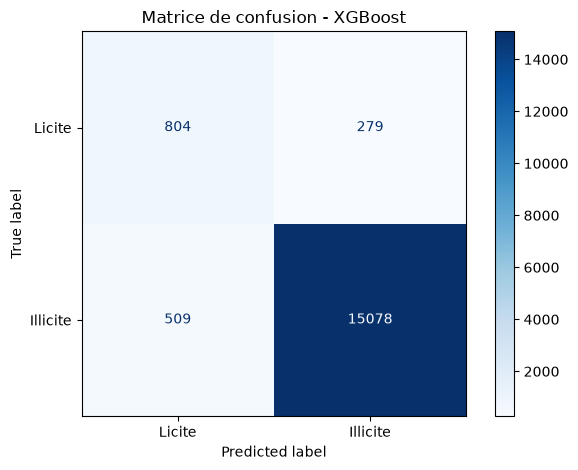

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    model_xgb,
    X_test,
    y_test,
    display_labels=["Licite", "Illicite"],
    cmap="Blues"
)

plt.title("Matrice de confusion - XGBoost")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    model_xgb.predict(X_test),
    labels=[0, 1],
    target_names=["Licite", "Illicite"],
    digits=4
))

              precision    recall  f1-score   support

      Licite     0.6123    0.7424    0.6711      1083
    Illicite     0.9818    0.9673    0.9745     15587

    accuracy                         0.9527     16670
   macro avg     0.7971    0.8549    0.8228     16670
weighted avg     0.9578    0.9527    0.9548     16670



In [19]:
import joblib
from pathlib import Path

dossier_modeles = Path("models")
dossier_modeles.mkdir(exist_ok=True)

joblib.dump(model_xgb, dossier_modeles / "xgboost_blockchain.pkl")

print("Modèle XGBoost sauvegardé avec succès !")

Modèle XGBoost sauvegardé avec succès !


In [20]:
from pathlib import Path

fichier = Path("models/xgboost_blockchain.pkl")

print("Fichier présent :", fichier.exists())
print("Taille (Mo) :", round(fichier.stat().st_size / (1024 * 1024), 2)
      if fichier.exists() else "Fichier introuvable")

Fichier présent : True
Taille (Mo) : 0.36
